# Decentralized MARL for AoI Optimization
This notebook provides an interactive simulation environment for testing the decentralized Q-learning scheduling policy against Round Robin and Random Access baselines. 

Adjust the configuration variables below to see how network size, learning rate, and battery thresholds affect information freshness.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURATION VARIABLES
# ==========================================
NUM_SENSORS       = 10     # Try 10, 25, or 50
POWER_BUDGET      = 10     # Default battery capacity for all sensors
RECHARGE_THRESHOLD= 5      # T1: Battery level at which recharging starts
NUM_TIME_SLOTS    = 100    # Time slots per evaluation episode
NUM_EPISODES      = NUM_SENSORS * 1000  # Total training episodes
NUM_EVAL_EPISODES = 1000    # Number of greedy episodes to average for results

# Q-Learning Hyperparameters
ALPHA             = 0.05   # Learning rate
GAMMA             = 0.75   # Discount factor
EPSILON_START     = 1.0    # Initial exploration rate
EPSILON_END       = 0.05   # Final exploration rate

# Set a seed for reproducibility
random.seed(4)

In [2]:
# ==========================================
# SIMULATION CLASSES (WSN, Sensor, Monitor)
# ==========================================
WAIT, TRANSMIT = 0, 1
ACTIONS = [WAIT, TRANSMIT]
IDLE, SUCCESS, COLLISION = 0, 1, 2

class Battery:
    def __init__(self, power_level, t1_override=None):
        self.max_level = power_level
        self.power_level = power_level
        self.T1 = t1_override if t1_override is not None else power_level // 2
        self.T2 = 1

    def recharge(self):
        if self.power_level <= self.T1:
            self.power_level = min(self.power_level + 1, self.max_level)

class Sensor:
    def __init__(self, power_budget, a_max, alpha, gamma, t1_override=None):
        self.power_budget = power_budget
        self.battery = Battery(power_budget, t1_override=t1_override)
        self.time_since_last_tx = 0
        self.last_outcome = IDLE
        self.q_table = {}
        self.a_max = a_max
        self.alpha = alpha
        self.gamma = gamma

    def get_reward(self, aoi):
        base = 2.0 if self.last_outcome == SUCCESS else (-2.0 if self.last_outcome == COLLISION else -0.5)
        return base + -2.0 * (min(aoi, self.a_max) / self.a_max)

    def reset(self):
        self.time_since_last_tx = 0
        self.last_outcome = IDLE
        self.battery.power_level = self.power_budget

    def age(self):
        self.time_since_last_tx += 1

    def get_state(self):
        return (min(self.time_since_last_tx, self.a_max), self.last_outcome, self.battery.power_level)

    def choose_action(self, state, epsilon):
        available = [WAIT] if self.battery.power_level <= self.battery.T2 else ACTIONS
        if random.random() < epsilon:
            return random.choice(available)
        q_vals = {a: self.q_table.get((state, a), 0.0) for a in available}
        max_q = max(q_vals.values())
        return random.choice([a for a, q in q_vals.items() if q == max_q])

class Monitor:
    def __init__(self, num_sensors):
        self.num_sensors = num_sensors
        self.time = 0
        self.last_received_time = [0] * num_sensors

    def update_on_arrival(self, sid, gen_time):
        self.last_received_time[sid] = gen_time

    def get_aoi(self, sid):
        return max(0, self.time - self.last_received_time[sid])

    def get_avg_aoi(self):
        return sum(self.get_aoi(i) for i in range(self.num_sensors)) / self.num_sensors

class WSN:
    def __init__(self, num_sensors, alpha, gamma, t1_override, power_budget):
        self.num_sensors = num_sensors
        self.alpha = alpha
        self.gamma = gamma
        self.a_max = num_sensors * 4
        self.time = 0
        self.monitor = Monitor(num_sensors)
        self.past_rewards = []
        self.in_flight = []
        self.sensors = [Sensor(power_budget, self.a_max, alpha, gamma, t1_override) for _ in range(num_sensors)]

    def step(self, actions, learn=True):
        self.time += 1
        self.monitor.time = self.time

        for pkt in self.in_flight[:]:
            arr, sid, gen = pkt
            if arr <= self.time:
                self.monitor.update_on_arrival(sid, gen)
                self.in_flight.remove(pkt)

        for i, s in enumerate(self.sensors):
            if actions[i] == TRANSMIT and s.battery.power_level <= s.battery.T2:
                actions[i] = WAIT

        states = [s.get_state() for s in self.sensors]
        transmitting = [i for i, a in enumerate(actions) if a == TRANSMIT]

        if len(transmitting) == 1:
            idx = transmitting[0]
            self.in_flight.append((self.time + random.randint(1, 3), idx, self.time))
            self.sensors[idx].last_outcome = SUCCESS
            self.sensors[idx].battery.power_level -= 1
            self.sensors[idx].time_since_last_tx = 0
            for j, s in enumerate(self.sensors):
                if j != idx: s.last_outcome = IDLE
        elif len(transmitting) == 0:
            for s in self.sensors: s.last_outcome = IDLE
        else:
            tx_set = set(transmitting)
            for j, s in enumerate(self.sensors):
                s.last_outcome = COLLISION if j in tx_set else IDLE
                if j in tx_set:
                    s.battery.power_level = max(0, s.battery.power_level - 1)

        for j, s in enumerate(self.sensors):
            if not (len(transmitting) == 1 and j == transmitting[0]):
                s.age()

        for s in self.sensors: s.battery.recharge()

        next_states = [s.get_state() for s in self.sensors]
        rewards = [s.get_reward(self.monitor.get_aoi(i)) for i, s in enumerate(self.sensors)]

        if learn:
            for i, s in enumerate(self.sensors):
                st, a, r, sp = states[i], actions[i], rewards[i], next_states[i]
                avail_next = [WAIT] if s.battery.power_level <= s.battery.T2 else ACTIONS
                max_next = max(s.q_table.get((sp, ap), 0.0) for ap in avail_next)
                new_q = s.q_table.get((st, a), 0.0) + s.alpha * (r + s.gamma * max_next - s.q_table.get((st, a), 0.0))
                s.q_table[(st, a)] = new_q

        return sum(rewards)

    def reset(self):
        self.time = 0
        self.in_flight = []
        self.monitor = Monitor(self.num_sensors)
        for s in self.sensors: s.reset()

class RoundRobinPolicy:
    def __init__(self, num_sensors):
        self.num_sensors = num_sensors
        self.turn = 0

    def get_actions(self, sensors):
        actions = [WAIT] * self.num_sensors
        for _ in range(self.num_sensors):
            if sensors[self.turn].battery.power_level > sensors[self.turn].battery.T2:
                actions[self.turn] = TRANSMIT
                self.turn = (self.turn + 1) % self.num_sensors
                return actions
            self.turn = (self.turn + 1) % self.num_sensors
        return actions

def random_policy(sensors):
    n = len(sensors)
    return [WAIT if s.battery.power_level <= s.battery.T2 else (TRANSMIT if random.random() < 1/n else WAIT) for s in sensors]

In [3]:
# ==========================================
# TRAINING AND EVALUATION EXECUTION
# ==========================================
print(f"Initializing WSN with {NUM_SENSORS} sensors...")
network = WSN(NUM_SENSORS, ALPHA, GAMMA, RECHARGE_THRESHOLD, POWER_BUDGET)

eps_decay = (EPSILON_END / EPSILON_START) ** (1 / NUM_EPISODES)
epsilon = EPSILON_START

print(f"Training for {NUM_EPISODES} episodes...")
for ep in range(NUM_EPISODES):
    ep_ret = 0
    for t in range(NUM_TIME_SLOTS):
        actions = [s.choose_action(s.get_state(), epsilon) for s in network.sensors]
        ep_ret += network.step(actions, learn=True)
    network.past_rewards.append(ep_ret)
    epsilon *= eps_decay
    network.reset()

print(f"Evaluating policies over {NUM_EVAL_EPISODES} greedy episodes...")
avg_marl = [0.0] * NUM_TIME_SLOTS
avg_rand = [0.0] * NUM_TIME_SLOTS
avg_rr   = [0.0] * NUM_TIME_SLOTS

rr_net = WSN(NUM_SENSORS, ALPHA, GAMMA, RECHARGE_THRESHOLD, POWER_BUDGET)
rand_net = WSN(NUM_SENSORS, ALPHA, GAMMA, RECHARGE_THRESHOLD, POWER_BUDGET)
rr_policy = RoundRobinPolicy(NUM_SENSORS)

for ep in range(NUM_EVAL_EPISODES):
    network.reset(); rr_net.reset(); rand_net.reset(); rr_policy.turn = 0
    
    for t in range(NUM_TIME_SLOTS):
        # MARL (Frozen Q-tables)
        network.step([s.choose_action(s.get_state(), 0.0) for s in network.sensors], learn=False)
        avg_marl[t] += network.monitor.get_avg_aoi()
        
        # Round Robin
        rr_net.step(rr_policy.get_actions(rr_net.sensors), learn=False)
        avg_rr[t] += rr_net.monitor.get_avg_aoi()
        
        # Random Access
        rand_net.step(random_policy(rand_net.sensors), learn=False)
        avg_rand[t] += rand_net.monitor.get_avg_aoi()

avg_marl = [x / NUM_EVAL_EPISODES for x in avg_marl]
avg_rr = [x / NUM_EVAL_EPISODES for x in avg_rr]
avg_rand = [x / NUM_EVAL_EPISODES for x in avg_rand]

print("Simulation complete.")

Initializing WSN with 10 sensors...
Training for 10000 episodes...
Evaluating policies over 1000 greedy episodes...
Simulation complete.


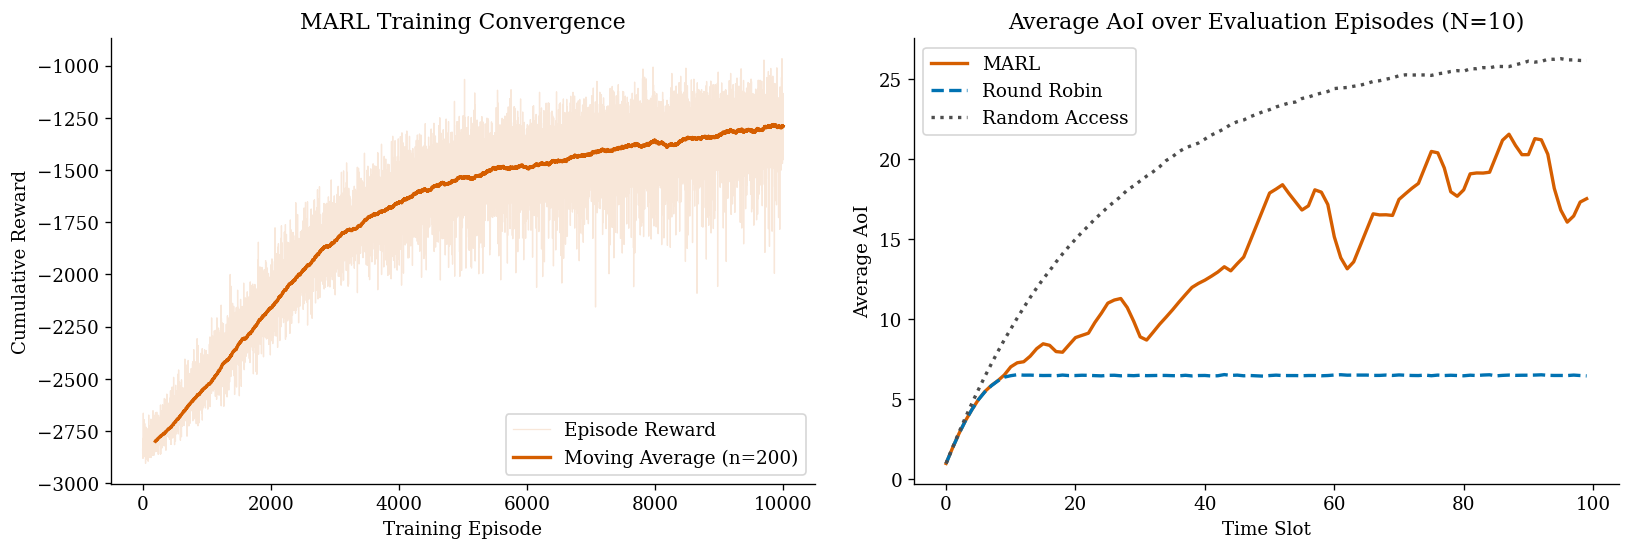

Final MARL AoI (Slot 100): 17.55
Final Round Robin AoI (Slot 100): 6.47
Final Random Access AoI (Slot 100): 26.18


In [4]:
# ==========================================
# PLOTTING RESULTS
# ==========================================
# Set up clean, presentation-ready styling
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 120,
})
colors = {'marl': '#D55E00', 'rr': '#0072B2', 'rand': '#4D4D4D'}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Training Convergence
raw_rewards = np.array(network.past_rewards)
window = 200
smoothed = np.convolve(raw_rewards, np.ones(window)/window, mode='valid')

ax1.plot(raw_rewards, alpha=0.15, color=colors['marl'], lw=0.8, label='Episode Reward')
ax1.plot(range(window-1, len(raw_rewards)), smoothed, color=colors['marl'], lw=2, label=f'Moving Average (n={window})')
ax1.set_title('MARL Training Convergence')
ax1.set_xlabel('Training Episode')
ax1.set_ylabel('Cumulative Reward')
ax1.legend(loc='lower right')

# Plot 2: AoI Baseline Comparison
ts = range(NUM_TIME_SLOTS)
ax2.plot(ts, avg_marl, color=colors['marl'], lw=2, label='MARL')
ax2.plot(ts, avg_rr, color=colors['rr'], lw=2, linestyle='--', label='Round Robin')
ax2.plot(ts, avg_rand, color=colors['rand'], lw=2, linestyle=':', label='Random Access')

ax2.set_title(f'Average AoI over Evaluation Episodes (N={NUM_SENSORS})')
ax2.set_xlabel('Time Slot')
ax2.set_ylabel('Average AoI')
ax2.legend(loc='upper left')

plt.tight_layout(pad=2.0)
plt.show()

print(f"Final MARL AoI (Slot {NUM_TIME_SLOTS}): {avg_marl[-1]:.2f}")
print(f"Final Round Robin AoI (Slot {NUM_TIME_SLOTS}): {avg_rr[-1]:.2f}")
print(f"Final Random Access AoI (Slot {NUM_TIME_SLOTS}): {avg_rand[-1]:.2f}")